# Human Action Recognition — sprawozdanie i analiza wyników (02)

**Przedmiot:** Podstawy reprezentacji i analizy danych
**Typ:** Projekt zaliczeniowy
**Autorzy:** Artsiom Markevich, Serafim Sidubayeu
**Data:** 31.01.2026
**Zbiór danych:** Human Action Recognition (obrazy + etykiety w pliku CSV)  
**Zadanie:** klasyfikacja obrazu do jednej z 15 klas aktywności (multi-class image classification)

Wymagania (zgodnie z poleceniem):  
1) opis zbioru danych (wg źródła)  
2) analiza eksploracyjna: miary + **wnioski**  
3) wizualizacje + **omówienie**  
4) część ML: opis zadania, metody, metryki, kod  
5) wyniki + **interpretacja**  
6) krótkie podsumowanie


## 0) Źródło danych

Zbiór danych zawiera **12 600 obrazów** przedstawiających ludzi wykonujących różne czynności (akcje).  
Etykiety klas znajdują się w pliku **Training_set.csv** (kolumny: `filename`, `label`), a same obrazy w folderze **train/**.  
Zadanie polega na przypisaniu każdemu obrazowi **jednej** z **15** klas aktywności (klasyfikacja wieloklasowa).  
Zbiór jest zbalansowany: **840 przykładów na klasę**, a liczba brakujących plików obrazów wynosi **0**.


In [3]:
import os, json, random
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

print("Python:", os.sys.version)
print("TensorFlow:", tf.__version__)


Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
TensorFlow: 2.16.1


In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_DIR = Path("./data/Human Action Recognition")
TRAIN_IMG_DIR = DATA_DIR / "train"
CSV_PATH = DATA_DIR / "Training_set.csv"

RESULTS_JSON = Path("./results.json")
CLASSES_JSON = Path("./classes.json")
MODELS_DIR = Path("./models")

IMG_SIZE = (160, 160)

print("CSV_PATH:", CSV_PATH.resolve())
print("TRAIN_IMG_DIR:", TRAIN_IMG_DIR.resolve())
print("RESULTS_JSON:", RESULTS_JSON.resolve())
print("MODELS_DIR:", MODELS_DIR.resolve())


CSV_PATH: C:\Users\marke\University\Python\PRIADPROJECT\data\Human Action Recognition\Training_set.csv
TRAIN_IMG_DIR: C:\Users\marke\University\Python\PRIADPROJECT\data\Human Action Recognition\train
RESULTS_JSON: C:\Users\marke\University\Python\PRIADPROJECT\results.json
MODELS_DIR: C:\Users\marke\University\Python\PRIADPROJECT\models


## 1) Opis danych + analiza eksploracyjna (EDA)

In [5]:
if not CSV_PATH.exists():
    raise FileNotFoundError(f"Brak pliku CSV: {CSV_PATH}")
if not TRAIN_IMG_DIR.exists():
    raise FileNotFoundError(f"Brak folderu z obrazami: {TRAIN_IMG_DIR}")

df = pd.read_csv(CSV_PATH)

required_cols = {"filename", "label"}
missing_cols = required_cols - set(df.columns)
if missing_cols:
    raise ValueError(f"CSV nie ma wymaganych kolumn {missing_cols}. Ma kolumny: {list(df.columns)}")

df["path"] = df["filename"].apply(lambda x: str(TRAIN_IMG_DIR / str(x)))

print("Liczba rekordów:", len(df))
print("Przykład wierszy:")
display(df.head(5))


Liczba rekordów: 12600
Przykład wierszy:


,filename,label,path
0,Image_1.jpg,sitting,data\Human Action Recognition\train\Image_1.jpg
1,Image_2.jpg,using_laptop,data\Human Action Recognition\train\Image_2.jpg
2,Image_3.jpg,hugging,data\Human Action Recognition\train\Image_3.jpg
3,Image_4.jpg,sleeping,data\Human Action Recognition\train\Image_4.jpg
4,Image_5.jpg,using_laptop,data\Human Action Recognition\train\Image_5.jpg


In [6]:
import json
from pathlib import Path

if Path("classes.json").exists():
    class_names = json.loads(Path("classes.json").read_text(encoding="utf-8"))
else:
    class_names = sorted(df["label"].unique())
num_classes = len(class_names)

counts = df["label"].value_counts().reindex(class_names)
missing_files = sum(1 for p in df["path"].tolist() if not Path(p).exists())

print("Liczba klas:", num_classes)
print("Liczba obrazów:", len(df))
print("Brakujących plików obrazów:", missing_files)

baseline_random_acc = 1.0 / num_classes
print("Baseline (losowe zgadywanie) accuracy ~", round(baseline_random_acc, 4))

display(counts.to_frame("count"))


Liczba klas: 15
Liczba obrazów: 12600
Brakujących plików obrazów: 0
Baseline (losowe zgadywanie) accuracy ~ 0.0667


,count
label,
calling,840
clapping,840
cycling,840
dancing,840
drinking,840
eating,840
fighting,840
hugging,840
laughing,840


**Wnioski (EDA – miary):**  
- Zbiór ma **15 klas** oraz **12 600** obrazów, więc baseline (losowe zgadywanie) wynosi **~0.0667** (1/15). Oznacza to, że nawet wynik ~0.20 byłby już wyraźnie lepszy od przypadku, a wartości około 0.70 wskazują na realne uczenie się cech akcji.  
- `Brakujących plików obrazów = 0` — dane są spójne: każdemu rekordowi w `Training_set.csv` odpowiada plik w folderze `train/`. To eliminuje typowy błąd projektu (złe ścieżki), który potrafi całkowicie zepsuć trening i ewaluację.  
- Rozkład klas jest **idealnie zbalansowany**: **840 przykładów na klasę**. Dzięki temu accuracy i macro F1 nie są sztucznie podbijane przez klasy częstsze, a model nie ma „motywacji”, aby zgadywać jedną dominującą etykietę.  
- Zbalansowanie pozwala uczciwie porównywać modele oraz analizować jakości per-klasa: różnice w F1 wynikają głównie z **trudności wizualnej** klas (podobne pozy, słabo widoczne obiekty), a nie z braku danych w danej klasie.  
- Przy równych liczebnościach klas łatwiej interpretować confusion matrix, bo wysoki udział pomyłek dla danej klasy oznacza realny problem rozróżniania, a nie efekt „małej próbki”.


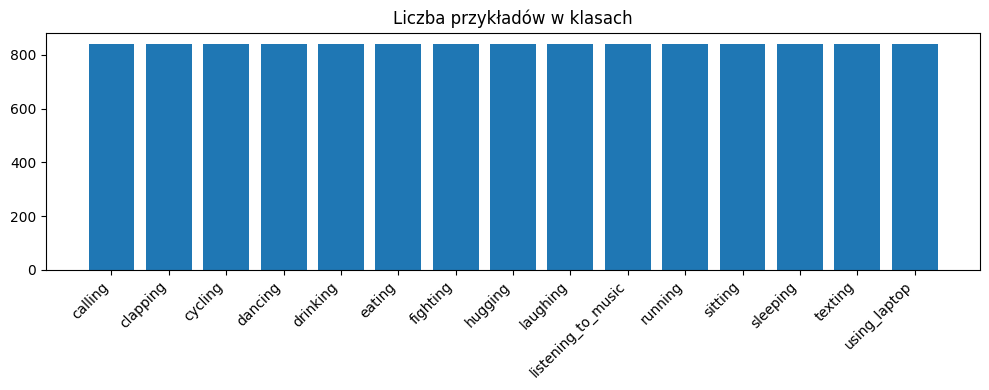

In [7]:
plt.figure(figsize=(10,4))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=45, ha="right")
plt.title("Liczba przykładów w klasach")
plt.tight_layout()
plt.show()


**Omówienie (rozkład klas):**  
- Słupki mają bardzo podobną wysokość, co potwierdza **zbalansowanie** klas (840/klasa).  
- Dzięki temu accuracy i macro F1 nie są “zawyżane” przez dominujące klasy.


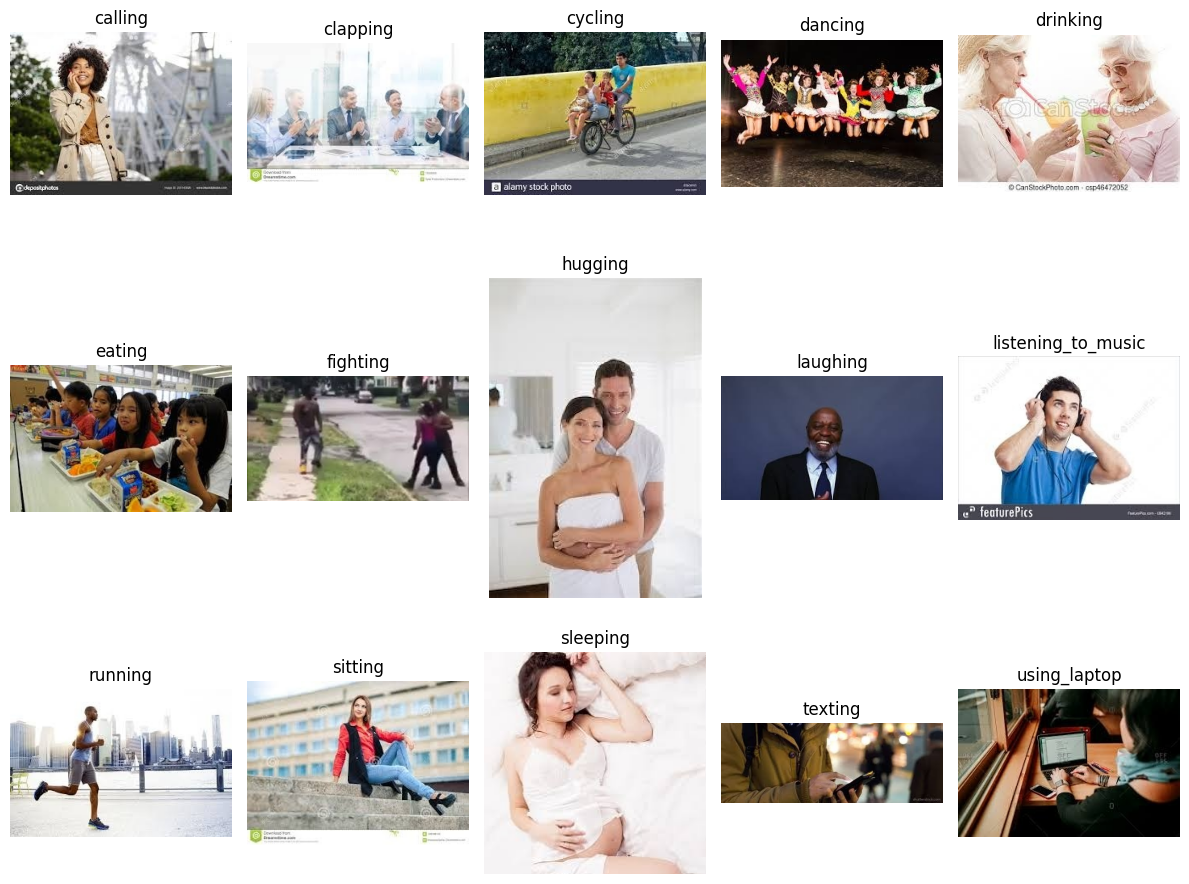

In [8]:
plt.figure(figsize=(12, 10))
cols = 5
rows = int(np.ceil(num_classes / cols))

for i, cls in enumerate(class_names):
    cls_rows = df[df["label"] == cls]
    sample_row = cls_rows.sample(1, random_state=SEED).iloc[0]
    img = tf.keras.utils.load_img(sample_row["path"])
    plt.subplot(rows, cols, i+1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(cls)

plt.tight_layout()
plt.show()


**Omówienie (wizualizacja przykładów):**  
- Na przykładach widać, że część klas jest łatwa do odróżnienia po scenie/pozie (np. **cycling**, **running**, **fighting**), a część może być wizualnie podobna (np. **calling**, **texting**, **listening_to_music**, **sitting**).  
- Podobieństwo wizualne klas zwykle prowadzi do większej liczby pomyłek między nimi w **confusion matrix**.


Próbka: 600
Wysokość: min/mean/max: 84 194.4 308
Szerokość:  min/mean/max: 126 263.1 360


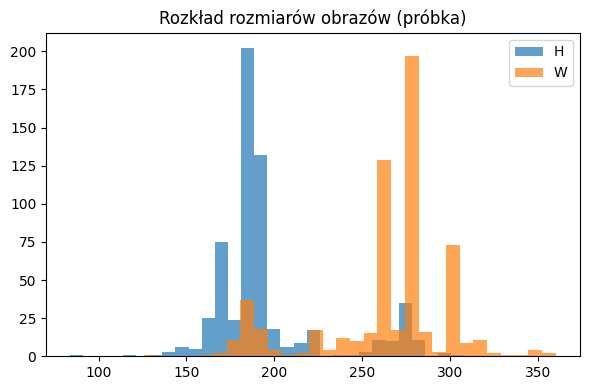

In [9]:
def read_shape(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    return int(img.shape[0]), int(img.shape[1])

sample_n = min(600, len(df))
sample_paths = df["path"].sample(sample_n, random_state=SEED).tolist()

shapes = np.array([read_shape(p) for p in sample_paths])  # (H, W)
h = shapes[:,0]
w = shapes[:,1]

print("Próbka:", sample_n)
print("Wysokość: min/mean/max:", int(h.min()), round(h.mean(),1), int(h.max()))
print("Szerokość:  min/mean/max:", int(w.min()), round(w.mean(),1), int(w.max()))

plt.figure(figsize=(6,4))
plt.hist(h, bins=30, alpha=0.7, label="H")
plt.hist(w, bins=30, alpha=0.7, label="W")
plt.title("Rozkład rozmiarów obrazów (próbka)")
plt.legend()
plt.tight_layout()
plt.show()


**Wnioski (rozmiary obrazów):**  
- Rozmiary obrazów są **zróżnicowane**, dlatego ujednolicenie przez `resize` jest konieczne przed podaniem danych do CNN.  
- W próbie 600 obrazów: wysokość **84–308 px** (średnio ~194), szerokość **126–360 px** (średnio ~263), co uzasadnia stały rozmiar wejścia `IMG_SIZE`.  
- Zbyt mały `IMG_SIZE` może obniżać jakość (utrata detali), a zbyt duży zwiększa czas obliczeń.


## 2) Uczenie maszynowe (ML) — zadanie, metody, metryki

**Zadanie:** klasyfikacja wieloklasowa (15 klas), wejście: obraz, wyjście: jedna etykieta akcji.  

**Metoda:** transfer learning (pretrenowane sieci na ImageNet) + fine-tuning.  
Uczenie w 2 etapach:
1) zamrożony backbone (uczymy tylko „głowę” klasyfikatora)  
2) częściowe odmrożenie backbone (fine-tuning z mniejszym learning rate)

**Modele porównywane:** ResNet50, EfficientNetB0, MobileNetV2.  

**Metryki:**  
- Accuracy (odsetek poprawnych predykcji)  
- Macro F1 (średnia F1 po klasach, traktuje wszystkie klasy równoważnie; ważne przy analizie jakości na poziomie klas)


In [10]:
if not RESULTS_JSON.exists():
    raise FileNotFoundError(f"Brak results.json: {RESULTS_JSON}. Najpierw uruchom notatnik 01.")

with open(RESULTS_JSON, "r", encoding="utf-8") as f:
    results = json.load(f)

if isinstance(results, list):
    results_by_model = {r["model"]: r for r in results}
elif isinstance(results, dict):
    # alternatywny format: dict
    results_by_model = results
else:
    raise TypeError("Nieznany format results.json")

summary_rows = []
for name, r in results_by_model.items():
    summary_rows.append({
        "model": name,
        "val_acc": r.get("val_acc"),
        "macro_f1": r.get("macro_f1"),
        "saved_model": r.get("saved_model", str(MODELS_DIR / f"{name}.keras")),
    })

summary = pd.DataFrame(summary_rows).sort_values(by=["val_acc", "macro_f1"], ascending=False)
display(summary)


,model,val_acc,macro_f1,saved_model
0,resnet50,0.705556,0.707056,models\resnet50.keras
2,mobilenetv2,0.697619,0.691902,models\mobilenetv2.keras
1,efficientnetb0,0.697222,0.700238,models\efficientnetb0.keras


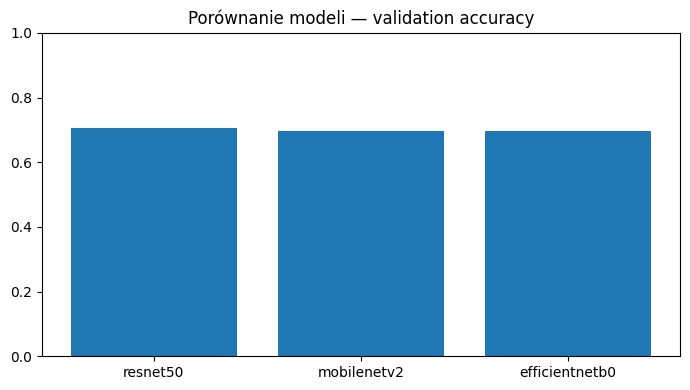

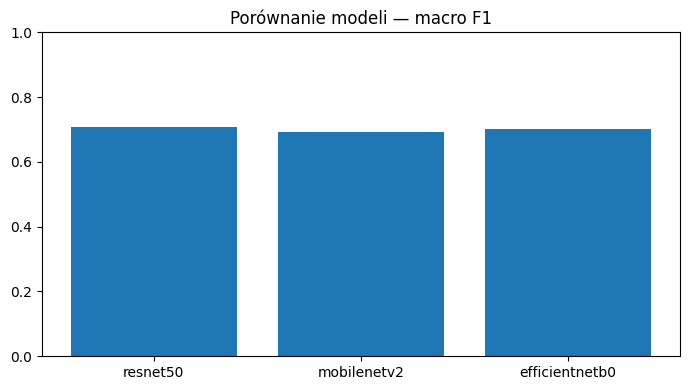

In [11]:
plt.figure(figsize=(7,4))
plt.bar(summary["model"], summary["val_acc"])
plt.title("Porównanie modeli — validation accuracy")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,4))
plt.bar(summary["model"], summary["macro_f1"])
plt.title("Porównanie modeli — macro F1")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


### Dodatkowe wykresy porównawcze (opcjonalnie)

Poniższe wykresy pomagają szybko ocenić relację między metrykami oraz różnice jakości między modelami.

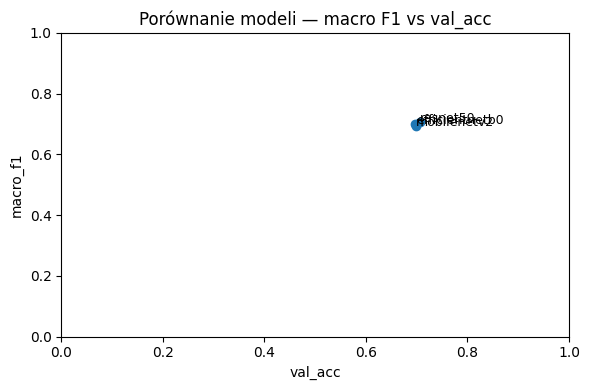

In [12]:
plt.figure(figsize=(6,4))
plt.scatter(summary["val_acc"], summary["macro_f1"])
for _, r in summary.iterrows():
    plt.text(float(r["val_acc"]) + 0.001, float(r["macro_f1"]) + 0.001, str(r["model"]), fontsize=9)
plt.xlabel("val_acc")
plt.ylabel("macro_f1")
plt.title("Porównanie modeli — macro F1 vs val_acc")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


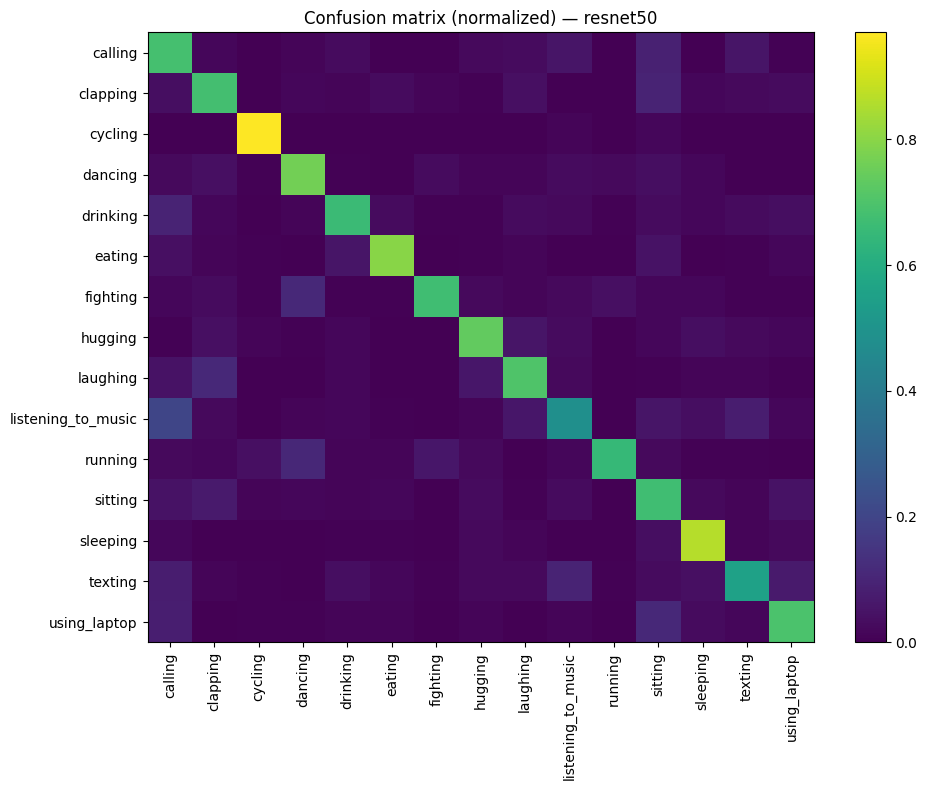

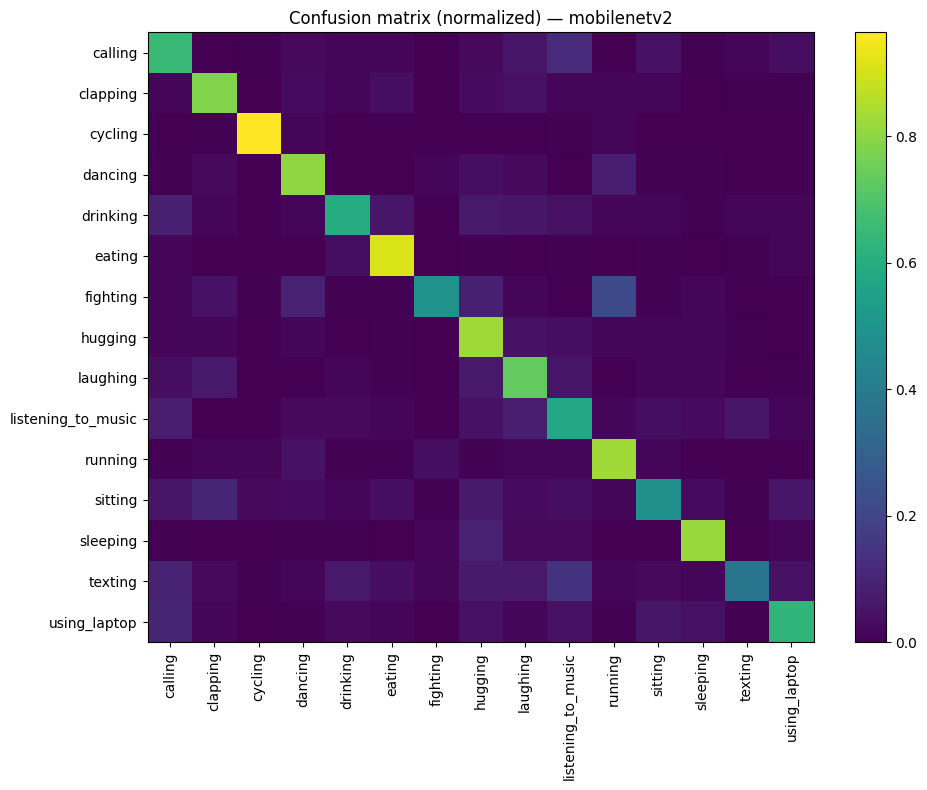

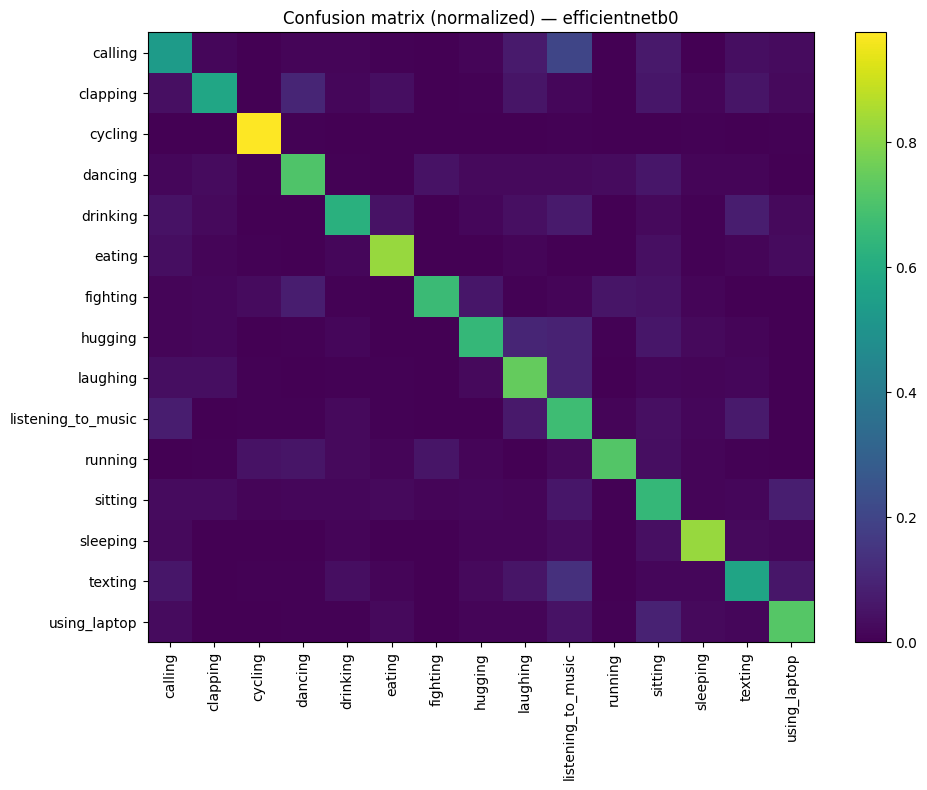

In [13]:

for name in summary["model"].tolist():
    cm_m = np.array(results_by_model[name]["cm"], dtype=np.int32)
    cm_m_norm = cm_m / cm_m.sum(axis=1, keepdims=True)

    plt.figure(figsize=(10,8))
    plt.imshow(cm_m_norm, aspect="auto")
    plt.colorbar()
    plt.xticks(range(len(class_names)), class_names, rotation=90)
    plt.yticks(range(len(class_names)), class_names)
    plt.title(f"Confusion matrix (normalized) — {name}")
    plt.tight_layout()
    plt.show()


**Interpretacja porównania:**  
- Accuracy pokazuje ogólną poprawność.  
- Macro F1 pokazuje, czy model działa dobrze „równo” na wszystkich klasach.  
- Jako „najlepszy” wybieramy model z najwyższym `val_acc` (a przy zbliżonych wynikach patrzymy na `macro_f1`).


In [14]:
best_row = summary.iloc[0]
best_model_name = str(best_row["model"])
print("Best model:", best_model_name)

best = results_by_model[best_model_name]
report = best["report"]
cm = np.array(best["cm"], dtype=np.int32)

# klasy
if CLASSES_JSON.exists():
    class_names = json.loads(CLASSES_JSON.read_text(encoding="utf-8"))
else:
    class_names = [k for k in report.keys() if k not in ["accuracy", "macro avg", "weighted avg"]]

print("Num classes:", len(class_names))


Best model: resnet50
Num classes: 15


In [15]:
per_class = []
for cls in class_names:
    if cls in report:
        per_class.append({
            "class": cls,
            "precision": report[cls]["precision"],
            "recall": report[cls]["recall"],
            "f1": report[cls]["f1-score"],
            "support": report[cls]["support"],
        })

per_class_df = pd.DataFrame(per_class).sort_values(by="f1", ascending=False)
display(per_class_df)


,class,precision,recall,f1,support
2,cycling,0.910615,0.970238,0.939481,168.0
5,eating,0.853503,0.797619,0.824615,168.0
12,sleeping,0.771277,0.863095,0.814607,168.0
6,fighting,0.856061,0.672619,0.753333,168.0
10,running,0.893443,0.648810,0.751724,168.0
7,hugging,0.738095,0.738095,0.738095,168.0
3,dancing,0.715084,0.761905,0.737752,168.0
14,using_laptop,0.713415,0.696429,0.704819,168.0
8,laughing,0.706587,0.702381,0.704478,168.0
4,drinking,0.735099,0.660714,0.695925,168.0


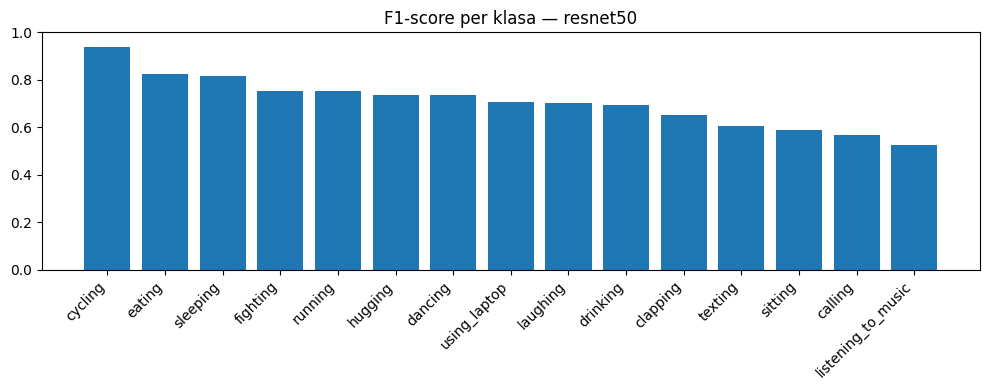

,top_class,f1
2,cycling,0.939481
5,eating,0.824615
12,sleeping,0.814607


,bottom_class,f1
13,texting,0.603896
11,sitting,0.588542
0,calling,0.569307
9,listening_to_music,0.525974


In [16]:
plt.figure(figsize=(10,4))
plt.bar(per_class_df["class"], per_class_df["f1"])
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.title(f"F1-score per klasa — {best_model_name}")
plt.tight_layout()
plt.show()

top3 = per_class_df.head(3)[["class","f1"]]
bot4 = per_class_df.tail(4)[["class","f1"]]
display(top3.rename(columns={"class":"top_class","f1":"f1"}))
display(bot4.rename(columns={"class":"bottom_class","f1":"f1"}))


**Interpretacja per-klasa:**  
- Wysoki F1 oznacza, że model dobrze rozpoznaje daną klasę (mało fałszywych alarmów i mało pominięć).  
- Niskie F1 zwykle oznacza podobieństwo wizualne do innych klas albo brak charakterystycznych cech (np. telefon/nawyk słabo widoczny).


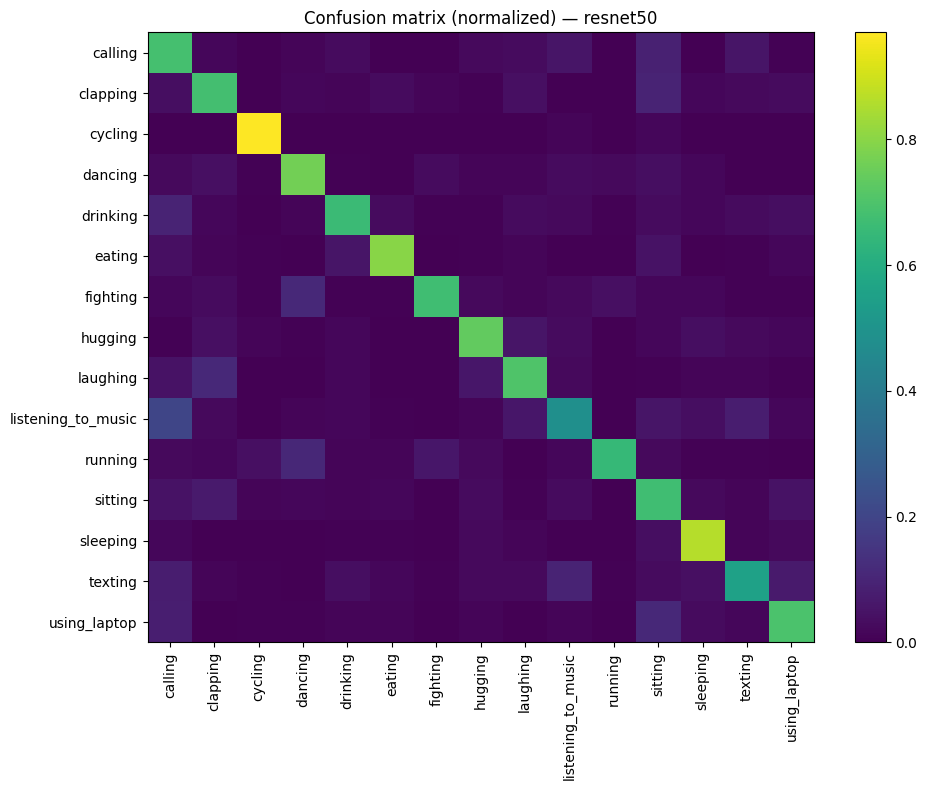

In [17]:
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(10,8))
plt.imshow(cm_norm, aspect="auto")
plt.colorbar()
plt.xticks(range(len(class_names)), class_names, rotation=90)
plt.yticks(range(len(class_names)), class_names)
plt.title(f"Confusion matrix (normalized) — {best_model_name}")
plt.tight_layout()
plt.show()


In [18]:
pairs = []
for i, true_cls in enumerate(class_names):
    row = cm_norm[i].copy()
    row[i] = 0.0
    j = int(np.argmax(row))
    pairs.append({
        "true": true_cls,
        "pred_most_often": class_names[j],
        "rate": float(cm_norm[i, j]),
        "count": int(cm[i, j]),
    })

top_conf = pd.DataFrame(pairs).sort_values(by="rate", ascending=False)
display(top_conf.head(10))


,true,pred_most_often,rate,count
9,listening_to_music,calling,0.202381,34
6,fighting,dancing,0.113095,19
8,laughing,clapping,0.113095,19
14,using_laptop,sitting,0.113095,19
10,running,dancing,0.107143,18
1,clapping,sitting,0.095238,16
4,drinking,calling,0.095238,16
13,texting,listening_to_music,0.095238,16
0,calling,sitting,0.089286,15
11,sitting,clapping,0.071429,12


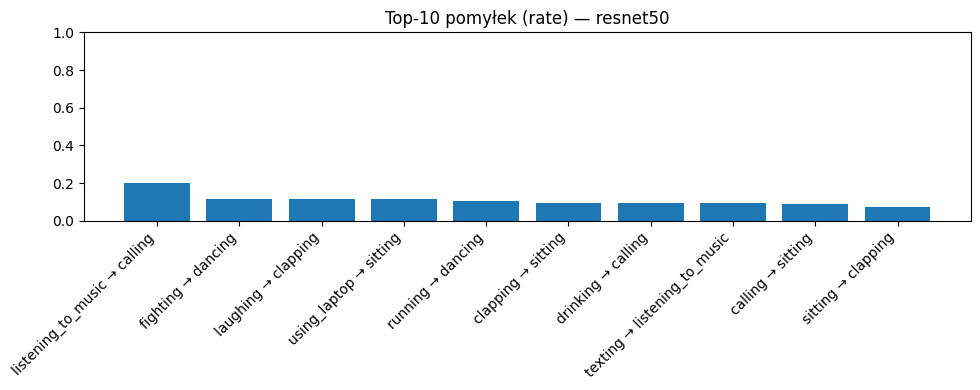

In [19]:
top10 = top_conf.head(10).copy()
top10["pair"] = top10["true"] + " → " + top10["pred_most_often"]

plt.figure(figsize=(10,4))
plt.bar(top10["pair"], top10["rate"])
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.title(f"Top-10 pomyłek (rate) — {best_model_name}")
plt.tight_layout()
plt.show()


**Interpretacja błędów:**  
- Tabela „top pomyłki” pokazuje, z jaką klasą najczęściej myli się dana prawdziwa klasa.  
- Najczęściej mylone pary warto omówić na podstawie podobieństwa póz / obiektów na obrazach.


## 3) Kod użycia modelu (demo) — jak działa na nowych obrazach

In [20]:
import tensorflow as tf
from tensorflow import keras

candidates = [
    MODELS_DIR / f"{best_model_name}.keras",
    MODELS_DIR / f"best_{best_model_name}.keras",
    Path(f"{best_model_name}.keras"),
    Path(f"best_{best_model_name}.keras"),
]

model_path = None
for p in candidates:
    if p.exists():
        model_path = p
        break

if model_path is None:
    raise FileNotFoundError(
        "Nie znaleziono pliku modelu. Sprawdzone ścieżki:\n" + "\n".join(str(p) for p in candidates)
    )

model = keras.models.load_model(str(model_path))
print("Loaded model:", model_path)


Loaded model: models\resnet50.keras


Example image: data\Human Action Recognition\train\Image_1.jpg


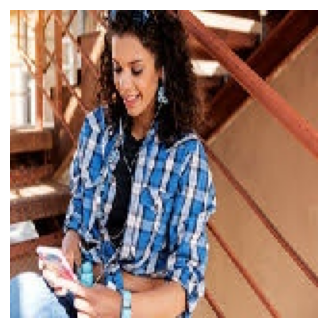

,rank,class,prob
0,1,sitting,0.630109
1,2,listening_to_music,0.154783
2,3,using_laptop,0.081653
3,4,calling,0.056264
4,5,texting,0.054469


In [21]:
def load_image_for_model(image_path: str | Path, img_size=IMG_SIZE):
    image_path = str(image_path)
    img = tf.keras.utils.load_img(image_path, target_size=img_size)
    arr = tf.keras.utils.img_to_array(img)
    return img, np.expand_dims(arr, axis=0)

def predict_topk(image_path: str | Path, k=5):
    img, x = load_image_for_model(image_path)
    probs = model.predict(x, verbose=0)[0]
    top_idx = np.argsort(probs)[::-1][:k]

    plt.figure(figsize=(4,4))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

    out = []
    for rank, i in enumerate(top_idx, start=1):
        out.append({"rank": rank, "class": class_names[i], "prob": float(probs[i])})
    return pd.DataFrame(out)

EXAMPLE_IMAGE = Path(TRAIN_IMG_DIR) / df.iloc[0]["filename"]
print("Example image:", EXAMPLE_IMAGE)
display(predict_topk(EXAMPLE_IMAGE, k=5))


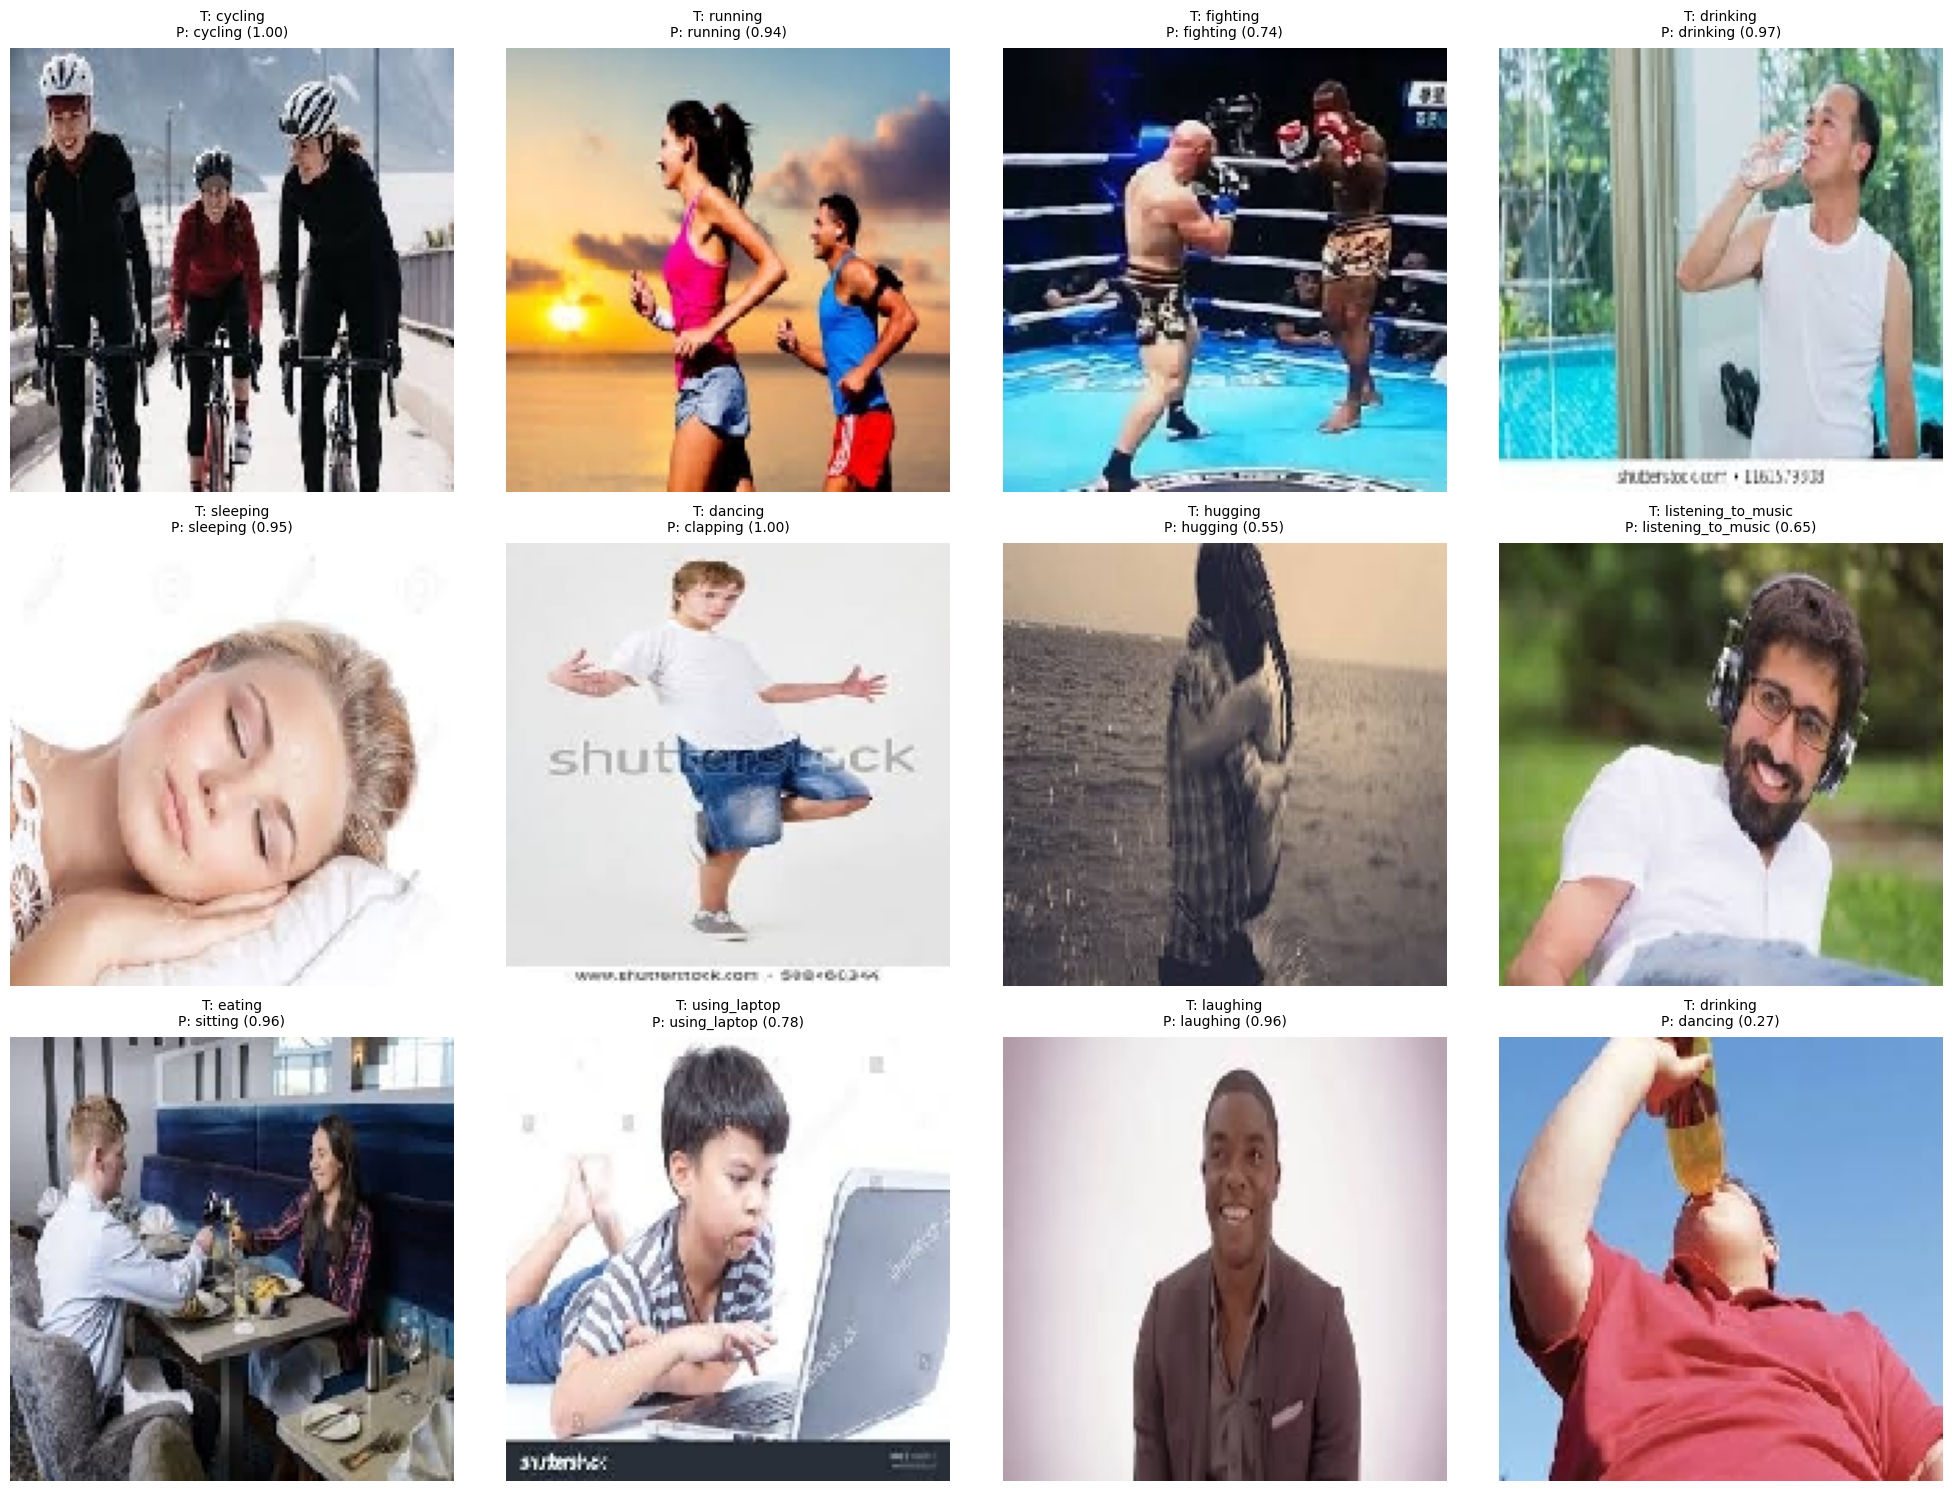

Błędy w próbce: 3/12


In [22]:
N = 12
sample = df.sample(N, random_state=SEED).reset_index(drop=True)

cols = 4
rows = int(np.ceil(N / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols*5, rows*5))
axes = np.array(axes).reshape(-1)

wrong = 0
for idx, row in sample.iterrows():
    true_label = row["label"]
    img, x = load_image_for_model(row["path"])
    probs = model.predict(x, verbose=0)[0]
    pred_label = class_names[int(np.argmax(probs))]

    if pred_label != true_label:
        wrong += 1

    ax = axes[idx]
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(f"T: {true_label}\nP: {pred_label} ({np.max(probs):.2f})", fontsize=10, pad=8)

for j in range(N, len(axes)):
    axes[j].axis("off")

fig.tight_layout()
plt.show()
print(f"Błędy w próbce: {wrong}/{N}")



**Wnioski (demo):**  
- Ten fragment pokazuje praktyczne użycie modelu: wejście = obraz, wyjście = top-k klas z prawdopodobieństwami.  
- Siatka `true vs pred` pozwala szybko zobaczyć, gdzie model się myli i czy te pomyłki są „zrozumiałe” (podobne klasy).


## 4) Podsumowanie (krótkie)

- Zbiór danych zawiera **12 600** obrazów w **15** klasach i jest zbalansowany (po **840** przykładów na klasę), bez brakujących plików.  
- Porównano trzy modele transfer learning: **ResNet50**, **EfficientNetB0** oraz **MobileNetV2**, uczone w 2 etapach (zamrożony backbone + fine-tuning).  
- Najlepszy wynik uzyskał **ResNet50**: `val_acc = 0.7056`, `macro_f1 = 0.7071`.  
- Najlepiej rozpoznawane klasy to **cycling**, **eating**, **sleeping**, a najsłabsze to **listening_to_music**, **calling**, **sitting**, **texting**.  
- Najczęstsze pomyłki wynikają z podobieństwa pozy i słabo widocznych obiektów (np. **listening_to_music → calling**, **using_laptop → sitting**, **running → dancing**).  
- Demo działania modelu na losowych obrazach potwierdza praktyczne użycie i pokazuje, że błędy występują głównie w klasach najbardziej podobnych wizualnie.
